# ICT-4204: Mobile and Cellular Communication Laboratory
## Combined Laboratory Codebook: Experiments 03, 08, and 09
### Frequency Allocation, Cell Splitting & Cellular Traffic Capacity Analysis

**Course Title:** Mobile and Cellular Communication Laboratory  
**Course Code:** ICT-4204  
**Department:** Department of Information and Communication Technology  
**University:** Islamic University, Kushtia, Bangladesh

---

### <a id="toc"></a>Table of Contents

- [**Experiment 03:** Study of Frequency Allocation and Channel Assignment in Cellular Networks](#exp03)
- [**Experiment 08:** Analysis of Cell Coverage, Cell Radius, and Cell Splitting](#exp08)
- [**Experiment 09:** Cellular Traffic, Channel Capacity, and Erlang-B Blocking Probability Analysis](#exp09)

---


<a id="exp03"></a>

# Experiment 03: Study of Frequency Allocation and Channel Assignment in Cellular Networks

**Course:** Mobile and Cellular Communication Laboratory  
**Course Code:** ICT-4204  
**Department:** Department of Information and Communication Technology, Islamic University, Kushtia, Bangladesh  
**Implementation:** Python / Jupyter Notebook

---
**Course-source basis:** Chapter 5 (Frequency Management and Channel Assignment) and the course Master Study Notes.

> This notebook is an educational laboratory implementation. It keeps the mathematical model simple enough to explain in a practical examination while preserving the core cellular-communication ideas.


## Aim

To study frequency allocation and fixed channel assignment in cellular networks and visualize frequency distribution, hexagonal frequency reuse, and uplink/downlink channel mapping.

## Objectives

- Understand frequency management and channel assignment.
- Distinguish fixed and dynamic/non-fixed channel assignment.
- Allocate channels among cells using a simple reuse-friendly pattern.
- Simulate call demand, served calls, and blocked calls.
- Explain why fixed allocation can leave channels idle in one cell while another cell is congested.

## Theory

A cellular network divides a geographical service area into smaller regions called **cells**, each served by a base station. Because the available radio-frequency spectrum is limited, efficient frequency allocation and channel assignment are essential.

**Frequency Allocation:** The process of dividing available radio spectrum into frequency channels for communication.

**Channel Assignment:** The process of allocating specific frequency channels to cellular base stations or mobile users.

### Types of Channel Assignment

**1. Fixed Channel Assignment (FCA)**

In FCA, each cell has a predetermined channel set:

$$
\mathcal{C}_k=\{\text{channels permanently assigned to cell }k\}
$$

If every channel in $\mathcal{C}_k$ is busy, a new call in that cell is blocked even if another cell has idle channels.

**2. Dynamic / Non-Fixed Channel Assignment**

In dynamic or non-fixed assignment, channels are drawn from a common or adaptable pool according to current demand and interference conditions. This improves flexibility but requires more real-time control.

The MATLAB program demonstrates a simplified FCA scheme.

## Mathematical Formulation

### 1. Total Number of Channels

The number of available paired channels is

$$
M = \left\lfloor \frac{1000B}{b_w} \right\rfloor
$$

where:

- $M$ = total number of paired channels
- $B$ = available bandwidth per direction (MHz)
- $b_w$ = channel spacing (kHz)

Given:

$$
B = 25\text{ MHz}, \qquad b_w = 200\text{ kHz}
$$

Therefore,

$$
M = \frac{25\times1000}{200}=125
$$

Hence, the system contains **125 paired channels**.

### 2. Uplink and Downlink Frequencies

For channel number $k$, the uplink frequency is

$$
f_{UL}(k)=f_0+(k-1)\frac{b_w}{1000}
$$

The corresponding downlink frequency is

$$
f_{DL}(k)=f_{UL}(k)+\Delta f
$$

where:

- $f_0=890$ MHz is the first uplink frequency
- $\Delta f=45$ MHz is the duplex separation
- $k=1,2,\ldots,125$

Thus, the illustrated uplink and downlink frequency ranges are:

- Uplink: **890.0–914.8 MHz**
- Downlink: **935.0–959.8 MHz**

### 3. Cluster Size and Frequency Reuse

Frequency reuse allows the same channel groups to be used in sufficiently separated cells.

The cluster size is

$$
N=i^2+ij+j^2
$$

For $i=2$ and $j=1$,

$$
N=2^2+(2)(1)+1^2=7
$$

The frequency reuse factor is

$$
\frac{1}{N}=\frac{1}{7}
$$

The co-channel reuse distance is

$$
D=R\sqrt{3N}
$$

The reuse ratio is

$$
q=\frac{D}{R}=\sqrt{3N}
$$

For $N=7$,

$$
q=\sqrt{21}\approx4.583
$$

A larger reuse distance generally reduces co-channel interference but also reduces frequency-reuse efficiency.

### 4. Channel Distribution

The number of channels initially assigned to each frequency group is

$$
c=\left\lfloor\frac{M}{N}\right\rfloor
$$

With $M=125$ and $N=7$,

$$
125=7(17)+6
$$

Therefore:

- Groups F1–F6 receive 18 channels each.
- Group F7 receives 17 channels.

## Graphical Analysis

The MATLAB program produces four visualizations:

1. **Frequency Allocation:** Shows the allocation of uplink frequencies to seven cell groups.
2. **Channels per Cell:** Shows the number of channels assigned to each group.
3. **Hexagonal Frequency Reuse:** Illustrates how frequency groups F1–F7 repeat across a cellular network.
4. **Uplink and Downlink Mapping:** Shows paired frequencies separated by 45 MHz.

## Result and Discussion

The experiment successfully allocates 125 paired channels among seven frequency groups using fixed channel assignment.

The hexagonal layout demonstrates frequency reuse, while the uplink/downlink mapping illustrates duplex-frequency separation.

This is an illustrative frequency-planning model rather than a complete interference-aware cellular network simulation.

## Conclusion

Frequency allocation and fixed channel assignment were studied using MATLAB. The experiment demonstrates how limited radio spectrum can be divided, assigned, and reused to support cellular communication efficiently.


EXPERIMENT 03 - ILLUSTRATIVE FREQUENCY PLAN
Cluster size N: 7 (i=2, j=1)
Paired duplex channels: 125  (guard bands ignored)
Uplink range: 890.0 to 914.8 MHz
Downlink range: 935.0 to 959.8 MHz
Co-channel center distance: 4.583 km
Group 1: 18 channels
Group 2: 18 channels
Group 3: 18 channels
Group 4: 18 channels
Group 5: 18 channels
Group 6: 18 channels
Group 7: 17 channels


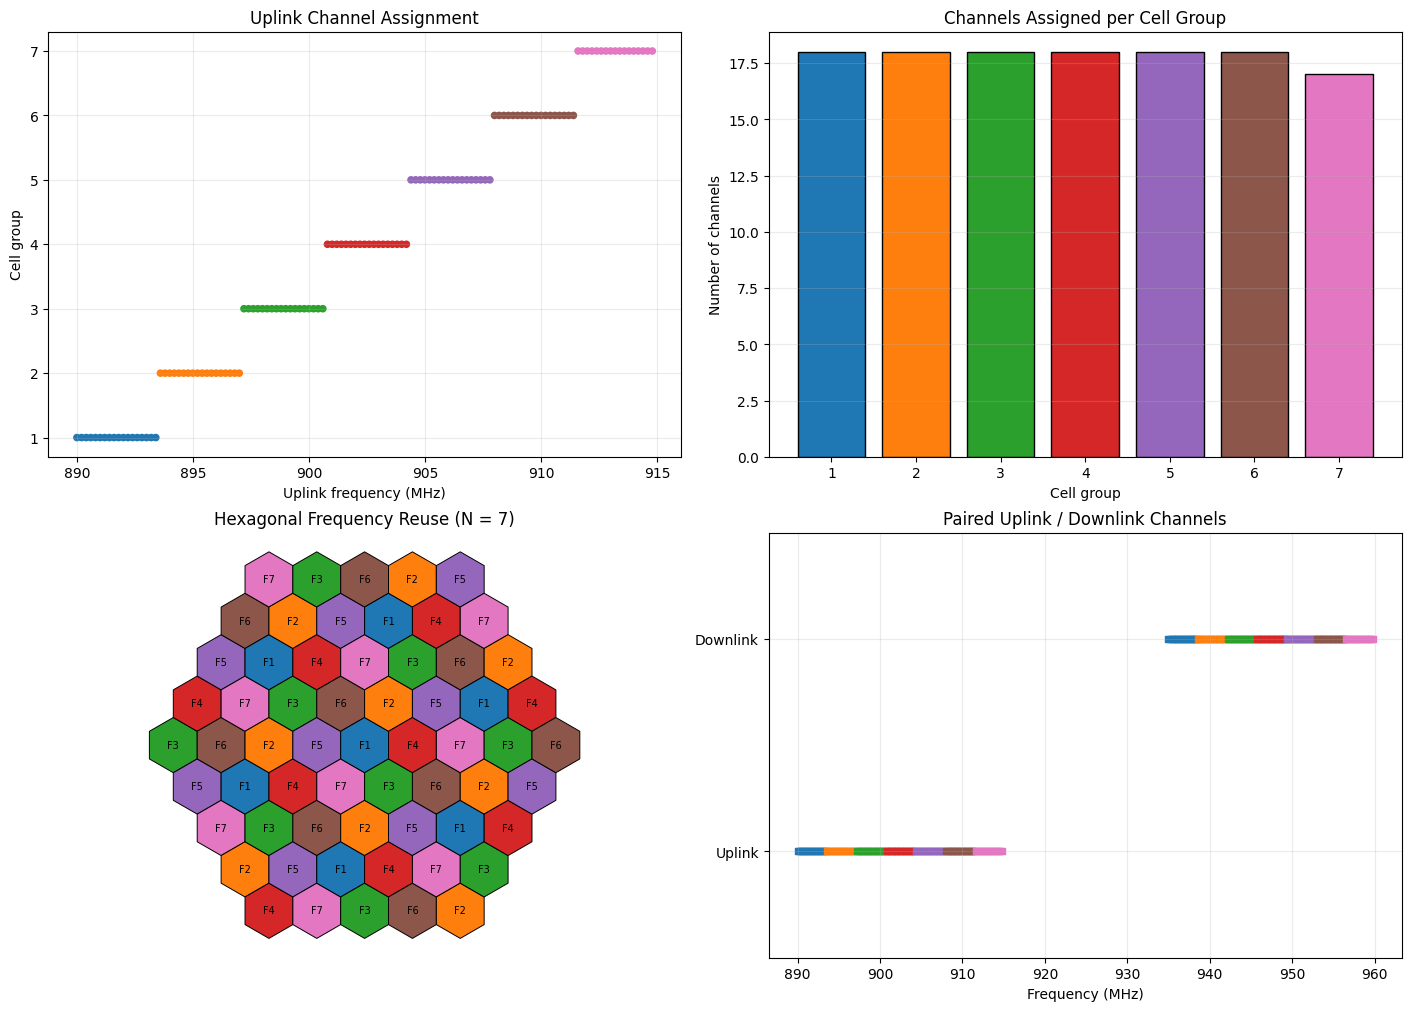

(7, 125, array([18, 18, 18, 18, 18, 18, 17]))

In [1]:
"""Experiment 03: Frequency allocation and channel assignment.

Python translation and simplification of the supplied classmate MATLAB E3 plot.
This is an ADDITIONAL 125-channel illustrative planning example; it does not
replace the existing EXP03 notebook's 70-channel traffic-demand example.

Uses only NumPy and Matplotlib. Run with:
    python EXP03_MATLAB_Style_Visualizations.py
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# Change these values to try another scenario.
BANDWIDTH_MHZ = 25.0       # illustrative spectrum in EACH direction
CHANNEL_SPACING_KHZ = 200.0
UPLINK_START_MHZ = 890.0
DUPLEX_SPACING_MHZ = 45.0
I, J = 2, 1                # reuse shift: N = I^2 + I*J + J^2 = 7
CELL_RADIUS_KM = 1.0
ASSIGNMENT = "sequential"  # or "interleaved"
GRID_RADIUS = 4            # rings of hexagonal cells shown in the plot


def allocate_channels(total_channels, group_count, method):
    """Assign channel numbers to group IDs 1..N using FCA."""
    if method == "interleaved":
        return np.arange(total_channels) % group_count + 1
    if method == "sequential":
        equal_count, remainder = divmod(total_channels, group_count)
        counts = [equal_count + (group < remainder)
                  for group in range(group_count)]
        return np.repeat(np.arange(1, group_count + 1), counts)
    raise ValueError("ASSIGNMENT must be 'sequential' or 'interleaved'")


def axial_to_xy(q, r, radius):
    """Hex-grid coordinates to kilometers for pointy-top hexagons."""
    return (np.sqrt(3) * radius * (q + r / 2), 1.5 * radius * r)


def hex_vertices(cx, cy, radius):
    """Vertices in consistent order so neighboring hexagons touch."""
    angles = np.deg2rad(np.arange(30, 390, 60))
    return np.column_stack((cx + radius * np.cos(angles),
                            cy + radius * np.sin(angles)))


def make_reuse_grid(i, j, ring_count):
    """Return (q, r, group) for a valid N=i^2+ij+j^2 reuse pattern.

    Two modular coordinates are used so the pattern also works for
    valid cases such as (i,j)=(2,0), where a one-residue trick fails.
    """
    n = i * i + i * j + j * j
    coords = [(q, r)
              for q in range(-ring_count, ring_count + 1)
              for r in range(-ring_count, ring_count + 1)
              if max(abs(q), abs(r), abs(q + r)) <= ring_count]

    def residue(q, r):
        return (((i + j) * q + j * r) % n,
                (-j * q + i * r) % n)

    residue_keys = sorted({residue(q, r) for q, r in coords})
    if len(residue_keys) != n:
        raise ValueError("Use more grid rings to display all frequency groups")
    group_by_key = {key: k + 1 for k, key in enumerate(residue_keys)}
    return [(q, r, group_by_key[residue(q, r)]) for q, r in coords]


def plot_frequency_planning(ul, dl, cell_group, counts, colors, reuse_grid, radius, n):
    """Recreate the four informative views from the MATLAB experiment."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
    ax1, ax2, ax3, ax4 = axes.flat

    # 1. Each point is one assigned uplink channel.
    ax1.scatter(ul, cell_group, s=20, c=colors[cell_group - 1])
    ax1.set(xlabel="Uplink frequency (MHz)", ylabel="Cell group",
            title="Uplink Channel Assignment")
    ax1.set_yticks(range(1, n + 1))
    ax1.grid(alpha=0.25)

    # 2. Channel capacity by group (not traffic demand).
    ax2.bar(range(1, n + 1), counts, color=colors, edgecolor="black")
    ax2.set(xlabel="Cell group", ylabel="Number of channels",
            title="Channels Assigned per Cell Group")
    ax2.set_xticks(range(1, n + 1))
    ax2.grid(axis="y", alpha=0.25)

    # 3. Hexagonal pattern: 7 frequencies are reused in distant cells.
    for q, r, group in reuse_grid:
        x, y = axial_to_xy(q, r, radius)
        ax3.add_patch(Polygon(hex_vertices(x, y, radius), closed=True,
                              facecolor=colors[group - 1],
                              edgecolor="black", linewidth=0.7))
        ax3.text(x, y, f"F{group}", ha="center", va="center", fontsize=7)
    ax3.set_aspect("equal", adjustable="box")
    ax3.relim()
    ax3.autoscale_view()
    ax3.axis("off")
    ax3.set_title(f"Hexagonal Frequency Reuse (N = {n})")

    # 4. Each uplink carrier has a downlink partner offset by DUPLEX_SPACING.
    ax4.scatter(ul, np.ones_like(ul), c=colors[cell_group - 1], s=19, marker="s")
    ax4.scatter(dl, np.ones_like(dl) * 2, c=colors[cell_group - 1], s=19, marker="s")
    ax4.set(xlabel="Frequency (MHz)", title="Paired Uplink / Downlink Channels")
    ax4.set_yticks([1, 2], ["Uplink", "Downlink"])
    ax4.set_ylim(0.5, 2.5)
    ax4.grid(alpha=0.25)
    return fig


def main(save_dir=None):
    n = I**2 + I*J + J**2
    if n < 1 or CHANNEL_SPACING_KHZ <= 0 or BANDWIDTH_MHZ <= 0:
        raise ValueError("Enter positive spectrum, channel spacing, and valid reuse indices")
    if CELL_RADIUS_KM <= 0:
        raise ValueError("Cell radius must be positive")

    total = int(np.floor(BANDWIDTH_MHZ * 1000 / CHANNEL_SPACING_KHZ))
    channel_ids = np.arange(1, total + 1)
    cell_group = allocate_channels(total, n, ASSIGNMENT)
    counts = np.bincount(cell_group, minlength=n + 1)[1:]
    uplink_mhz = UPLINK_START_MHZ + (channel_ids - 1) * CHANNEL_SPACING_KHZ / 1000
    downlink_mhz = uplink_mhz + DUPLEX_SPACING_MHZ
    reuse_grid = make_reuse_grid(I, J, GRID_RADIUS)

    # Exact physical check of the reuse distance for shift (I,J).
    x, y = axial_to_xy(I, J, CELL_RADIUS_KM)
    expected_d = CELL_RADIUS_KM * np.sqrt(3 * n)
    assert np.isclose(np.hypot(x, y), expected_d)
    assert len(reuse_grid) > 0 and len(np.unique([v[2] for v in reuse_grid])) == n
    assert counts.sum() == total

    print("EXPERIMENT 03 - ILLUSTRATIVE FREQUENCY PLAN")
    print(f"Cluster size N: {n} (i={I}, j={J})")
    print(f"Paired duplex channels: {total}  (guard bands ignored)")
    print(f"Uplink range: {uplink_mhz[0]:.1f} to {uplink_mhz[-1]:.1f} MHz")
    print(f"Downlink range: {downlink_mhz[0]:.1f} to {downlink_mhz[-1]:.1f} MHz")
    print(f"Co-channel center distance: {expected_d:.3f} km")
    for group, count in enumerate(counts, 1):
        print(f"Group {group}: {int(count)} channels")

    palette = np.array(plt.get_cmap("tab10").colors[:n])
    fig = plot_frequency_planning(uplink_mhz, downlink_mhz,
                                  cell_group, counts, palette,
                                  reuse_grid, CELL_RADIUS_KM, n)
    if save_dir is not None:
        from pathlib import Path
        out = Path(save_dir)
        out.mkdir(parents=True, exist_ok=True)
        fig.savefig(out / "EXP03_Frequency_Planning.png", dpi=170, bbox_inches="tight")
    else:
        plt.show()
    return n, total, counts



main()

**Extended observation.** The first six cell groups receive 18 channels each, and the last group receives 17, because $125 = 6\times18+17$. The hexagonal map repeats the same seven frequency groups at spatially separated cells. Uplink and downlink carriers form paired channels separated by 45 MHz. These plots complement (rather than replace) the earlier blocked-call FCA demonstration.

## Fixed vs Dynamic Assignment — Practical Comparison

| Feature | Fixed Channel Assignment | Dynamic / Non-Fixed Assignment |
|---|---|---|
| Channel ownership | Predetermined per cell | Selected according to current need |
| Complexity | Low | Higher |
| Signalling/control | Lower | Higher |
| Response to uneven traffic | Weak | Better |
| Call blocking under local congestion | Can be high | Can be reduced if reusable channels are available |
| Interference control | Planned in advance | Must be checked during assignment |

## Result and Discussion

The notebook allocates a fixed channel set to each cell and demonstrates local blocking under uneven traffic. This is the main weakness of FCA: resources cannot automatically move to a congested cell.

## Conclusion

Frequency allocation and fixed channel assignment were implemented successfully. The simulation clearly shows the difference between **system-wide unused capacity** and **local channel availability**.

## Viva Questions and Short Answers

1. **What is frequency management?**  
   Planning set-up/voice channels, channel numbering, and grouping according to the system plan.

2. **What is channel assignment?**  
   Allocation of radio channels to cells and mobile users.

3. **What is the main idea of FCA?**  
   Each cell receives a predetermined channel set.

4. **Why can FCA block a call even when the network has idle channels?**  
   Because idle channels in another cell are not automatically available to the congested cell.

5. **What is the main advantage of dynamic assignment?**  
   It adapts channel use to current traffic and can improve spectrum utilization.

---
[▲ Back to Table of Contents](#toc)
---


<a id="exp08"></a>

# Experiment 08: Analysis of Cell Coverage, Cell Radius, and Cell Splitting

**Course:** Mobile and Cellular Communication Laboratory (ICT-4204)  
**Implementation:** MATLAB and Python  
**Figures:** (1) Cell coverage area vs. radius, (2) Before-and-after cell splitting

## Aim

To study the relationship between cell radius and coverage area for circular and hexagonal cell models, and to illustrate how cell splitting reduces cell size and changes the required transmitter power.

## Objectives

1. Calculate the coverage area of circular and regular hexagonal cells.
2. Plot coverage area against cell radius for both models.
3. Illustrate an original hexagonal cell and a schematic cluster of seven smaller cells.
4. Calculate area and transmitter-power ratios after reducing the radius.
5. Explain how cell splitting can support greater frequency reuse and traffic capacity.

## 1. Theory of Cell Coverage and Cell Radius

**Cell coverage** is the geographic region in which a mobile station can obtain an acceptable received signal from a base station. Coverage is influenced by transmit power, antenna height and gain, frequency, terrain, obstacles, receiver sensitivity, and interference.

**Cell radius** is a simplified measure of coverage size. We use $R$ for the original-cell radius and $r$ for a smaller cell's radius. In a regular hexagon, the radius is measured from the center to a vertex.

### 1.1 Circular cell model

An omnidirectional base station is often illustrated using a circular coverage boundary. The ideal circular coverage area is

$$
A_{c}=\pi R^2.
$$

At $R=1\ \mathrm{km}$,

$$
A_c=\pi(1)^2\approx3.142\ \mathrm{km}^2.
$$

### 1.2 Hexagonal cell model

A regular hexagon is a convenient ideal model for cellular planning because identical hexagons can tile a plane without gaps or overlaps. A regular hexagon with center-to-vertex radius $R$ consists of six equilateral triangles, each of area $\sqrt{3}R^2/4$.

Therefore,

$$
A_h=6\left(\frac{\sqrt{3}}{4}R^2\right)
   =\frac{3\sqrt{3}}{2}R^2.
$$

At $R=1\ \mathrm{km}$,

$$
A_h=\frac{3\sqrt{3}}{2}(1)^2\approx2.598\ \mathrm{km}^2.
$$

**Comparison for equal center-to-vertex radius:**

$$
\frac{A_h}{A_c}=\frac{3\sqrt{3}}{2\pi}\approx0.827.
$$

Thus, a regular hexagonal cell occupies about $82.7\%$ of the area of a circle having the same radius. These are **geometric approximations**, not measured radio coverage boundaries.

### 1.3 Effect of cell radius on coverage area

Both models follow a square-law relationship:

$$
A\propto R^2,\qquad
\frac{A_2}{A_1}=\left(\frac{R_2}{R_1}\right)^2.
$$

Increasing the radius by a factor of two increases the ideal geometric area by a factor of four. **Figure 1** plots $A_c$ and $A_h$ against $R$, with the selected original and small-cell radii marked.

## 2. Theory of Cell Splitting

**Cell splitting** is a technique for increasing cellular capacity by replacing a relatively large, congested cell with smaller cells. Smaller cells permit radio resources to be reused more frequently across a service area, subject to appropriate frequency planning and interference control.

In the accompanying MATLAB-inspired illustration:

$$
R=1.00\ \mathrm{km},\qquad
r=0.35R=0.35\ \mathrm{km}.
$$

The area of one smaller hexagonal cell is

$$
A_{h,\mathrm{small}}=\frac{3\sqrt{3}}{2}r^2
=\frac{3\sqrt{3}}{2}(0.35)^2
\approx0.318\ \mathrm{km}^2.
$$

The **area ratio of one small cell to the original** is

$$
\frac{A_{h,\mathrm{small}}}{A_{h,\mathrm{old}}}
=\left(\frac{r}{R}\right)^2
=(0.35)^2=0.1225.
$$

Each small cell therefore has **12.25%** of the original cell's nominal hexagonal area. For the circular model, the same area ratio applies because circular area also scales as radius squared.

### 2.1 Transmitter power after splitting

For the simplified large-scale propagation relation

$$
P_r(d)\propto P_t d^{-n},
$$

where $n$ is the path-loss exponent, keeping the same received-power threshold at the respective cell boundaries gives

$$
\frac{P_{t,\mathrm{new}}}{P_{t,\mathrm{old}}}
=\left(\frac{r}{R}\right)^n.
$$

Using the course example $n=4$,

$$
\frac{P_{t,\mathrm{new}}}{P_{t,\mathrm{old}}}
=(0.35)^4\approx0.0150.
$$

In decibels,

$$
\Delta P_t=10\log_{10}(0.0150)\approx-18.24\ \mathrm{dB}.
$$

So one small cell needs about **1.50% of the original transmit power** under the same-threshold, same-environment model. This is a **relative model result**, not a measured base-station setting.

> **Important:** If the new radius is *half* the original radius, the separate example gives $(1/2)^4=1/16$ and $-12.04$ dB. The present code instead uses **$r=0.35R$**, so its correct value is **$0.35^4\approx0.0150$**.

### 2.2 Geometric arrangement in Figure 2

A center small cell is surrounded by six nearest neighbors. The distance between neighboring centers in a pointy-top hexagonal grid is

$$
d=\sqrt{3}\,r=\sqrt{3}(0.35)\approx0.606\ \mathrm{km}.
$$

**Figure 2** shows:

- **Before splitting:** one large hexagonal cell, its base station, and its radius $R$.
- **After splitting:** seven neighboring smaller cells, base-station markers, radius $r$, and a dashed *reference* outline of the old cell.

**Diagram limitation:** Seven cells with radius $0.35R$ are a **schematic cluster, not an exact partition** of the original cell. Their summed nominal areas equal $7(0.35)^2=0.8575$, or 85.75% of the old hexagonal cell area, and their outer boundary does not exactly match the dashed boundary. Do not interpret this sketch as proving an exact seven-fold increase in real network capacity.

## 3. Numerical Results

| Quantity | Formula | Result |
|---|---|---:|
| Original radius | $R$ | $1.000\ \mathrm{km}$ |
| New radius | $r=0.35R$ | $0.350\ \mathrm{km}$ |
| Original circular area | $\pi R^2$ | $3.142\ \mathrm{km}^2$ |
| New circular area | $\pi r^2$ | $0.385\ \mathrm{km}^2$ |
| Original hexagonal area | $3\sqrt{3}R^2/2$ | $2.598\ \mathrm{km}^2$ |
| New hexagonal area | $3\sqrt{3}r^2/2$ | $0.318\ \mathrm{km}^2$ |
| One-cell area ratio | $(r/R)^2$ | $0.1225=12.25\%$ |
| Nearest small-cell center spacing | $\sqrt{3}r$ | $0.606\ \mathrm{km}$ |
| Transmitter-power ratio ($n=4$) | $(r/R)^4$ | $0.0150=1.50\%$ |
| Relative transmitter-power change | $10\log_{10}(0.35^4)$ | $-18.24\ \mathrm{dB}$ |

## 4. Algorithm / Procedure

1. Set $R=1\ \mathrm{km}$, $r=0.35R$, and $n=4$.
2. Calculate circular and hexagonal areas for $R$ and $r$.
3. Plot both coverage-area formulas over a range of cell radii (**Figure 1**).
4. Compute the new-to-old area and transmit-power ratios.
5. Draw the original hexagonal cell with a base station and radius $R$.
6. Draw seven smaller neighboring hexagonal cells and their base stations (**Figure 2**).
7. Mark the small-cell radius $r$ and show the former boundary using a dashed line.
8. Compare the plots and record observations.


Old radius R = 1.00 km, small radius r = 0.35 km
Circle: old = 3.142, small = 0.385 km^2
Hexagon: old = 2.598, small = 0.318 km^2
Area ratio = 0.1225 (12.25%)
Power ratio = 0.01501 (-18.24 dB)
Small-cell center spacing = 0.606 km


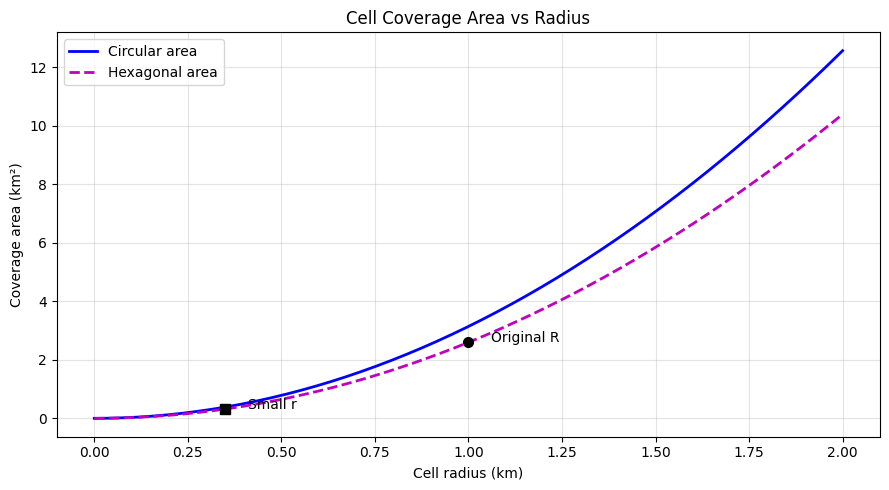

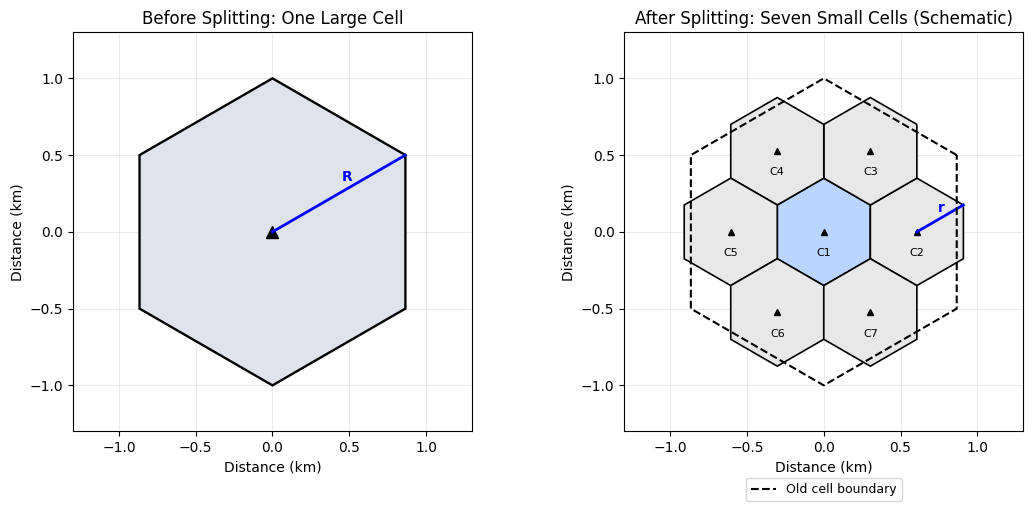

In [2]:
"""EXP08 - Cell Coverage, Radius and Cell Splitting (ICT-4204).

Figure 1: Circular and hexagonal coverage area vs radius.
Figure 2: One large cell before splitting and seven small cells afterward.
"""

import numpy as np
import matplotlib.pyplot as plt

# 1. Parameters (same as exp8.m)
R = 1.0                 # Original cell radius (km)
r = 0.35 * R            # Small-cell radius (km)
n = 4                   # Path-loss exponent

# 2. Coverage area and power calculations
Ac0 = np.pi * R**2
Ac1 = np.pi * r**2
Ah0 = (3 * np.sqrt(3) / 2) * R**2
Ah1 = (3 * np.sqrt(3) / 2) * r**2
P = (r / R)**n

d = np.sqrt(3) * r     # Center-to-center spacing of small cells

print(f"Old radius R = {R:.2f} km, small radius r = {r:.2f} km")
print(f"Circle: old = {Ac0:.3f}, small = {Ac1:.3f} km^2")
print(f"Hexagon: old = {Ah0:.3f}, small = {Ah1:.3f} km^2")
print(f"Area ratio = {(r/R)**2:.4f} ({100*(r/R)**2:.2f}%)")
print(f"Power ratio = {P:.5f} ({10*np.log10(P):.2f} dB)")
print(f"Small-cell center spacing = {d:.3f} km")

# 3. Figure 1 - Coverage area versus cell radius
rv = np.linspace(0, 2 * R, 200)
Ac = np.pi * rv**2
Ah = (3 * np.sqrt(3) / 2) * rv**2

plt.figure(figsize=(9, 5))
plt.plot(rv, Ac, "b-", lw=2, label="Circular area")
plt.plot(rv, Ah, "m--", lw=2, label="Hexagonal area")
plt.plot(R, Ah0, "ko", markersize=7)
plt.plot(r, Ah1, "ks", markersize=7)
plt.text(R + 0.06, Ah0, "Original R")
plt.text(r + 0.06, Ah1, "Small r")
plt.xlabel("Cell radius (km)")
plt.ylabel("Coverage area (km²)")
plt.title("Cell Coverage Area vs Radius")
plt.legend()
plt.grid(True, alpha=0.35)
plt.tight_layout()

# 4. Figure 2 - Before and after cell splitting
# Pointy-top hexagonal vertices; final point closes each boundary.
t = np.deg2rad(np.arange(30, 391, 60))
xy = np.array([
    [0, 0], [d, 0], [d / 2, 1.5 * r], [-d / 2, 1.5 * r],
    [-d, 0], [-d / 2, -1.5 * r], [d / 2, -1.5 * r]
])

fig, ax = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)

# Before: one large cell
ax[0].fill(R * np.cos(t), R * np.sin(t), color="#dee3ec", ec="black", lw=1.7)
ax[0].plot(0, 0, "k^", ms=9)  # Base station
ax[0].plot([0, R * np.cos(t[0])], [0, R * np.sin(t[0])], "b-", lw=2)
ax[0].text(0.45 * R, 0.33 * R, "R", color="blue", weight="bold")
ax[0].set_title("Before Splitting: One Large Cell")

# After: seven small hexagons (1 center + 6 neighbors)
for k, (x, y) in enumerate(xy, start=1):
    col = "#b8d6ff" if k == 1 else "#e8e8e8"
    ax[1].fill(x + r * np.cos(t), y + r * np.sin(t),
               color=col, ec="black", lw=1.2)
    ax[1].plot(x, y, "k^", ms=5)  # New base station
    ax[1].text(x, y - 0.45 * r, f"C{k}", ha="center", fontsize=8)

# Show radius r of small cell C2
x, y = xy[1]
ax[1].plot([x, x + r * np.cos(t[0])], [y, y + r * np.sin(t[0])], "b-", lw=2)
ax[1].text(x + 0.4 * r, y + 0.37 * r, "r", color="blue", weight="bold")

# Reference outline of original cell (not an exact partition)
ax[1].plot(R * np.cos(t), R * np.sin(t), "k--", lw=1.5,
           label="Old cell boundary")
ax[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.19), fontsize=9)
ax[1].set_title("After Splitting: Seven Small Cells (Schematic)")

for a in ax:
    a.set_aspect("equal", adjustable="box")
    a.set_xlim(-1.3 * R, 1.3 * R)
    a.set_ylim(-1.3 * R, 1.3 * R)
    a.set_xlabel("Distance (km)")
    a.set_ylabel("Distance (km)")
    a.grid(True, alpha=0.25)
    a.set_axisbelow(True)

plt.show()


## 5. Observations and Discussion

**Figure 1: Coverage Area vs Cell Radius.** Both circular and hexagonal cell areas increase quadratically with radius. For the same radius, circular area is larger than hexagonal area. Reducing the radius from 1 km to 0.35 km reduces each cell's nominal area to 12.25% of the original.

**Figure 2: Cell Splitting.** A single large base-station service area is replaced conceptually by seven smaller base-station service areas. This increases the density of cells and creates opportunities for higher traffic capacity, but it also requires additional infrastructure, careful channel planning, and potentially more handovers.

## 6. Advantages and Limitations

**Advantages:** Greater potential traffic capacity, more localized coverage management, and reduced per-cell transmission power under the model.

**Limitations:** Additional base stations and costs, more frequent handovers, interference-planning complexity, and idealized coverage assumptions.

## 7. Conclusion

The experiment verifies the square-law relationship between cell radius and coverage area for both circular and regular hexagonal models. It also visualizes a schematic seven-cell splitting arrangement and calculates the corresponding small-cell area and transmitter-power scaling. The plots jointly explain **coverage geometry** and the **purpose of cell splitting**.

## 8. Viva Questions and Short Answers

1. **What is cell coverage?** The area where a mobile receives an acceptable signal from a base station.
2. **Why use hexagons in cellular planning?** Regular hexagons tile the plane without geometric gaps and are convenient for frequency planning.
3. **How does area change when radius is halved?** It becomes one quarter of the original area.
4. **What is cell splitting?** Replacing a large cell with smaller cells to increase the density of cells and opportunities for frequency reuse.
5. **What is the area of a regular hexagonal cell?** $A=3\sqrt{3}R^2/2$ for center-to-vertex radius $R$.
6. **Why does transmitter power decrease after splitting?** A shorter required propagation distance allows a lower transmit power for the same modelled boundary signal threshold.
7. **What is the power ratio for $r=0.35R$ and $n=4$?** $0.35^4\approx0.0150$, about $-18.24$ dB.
8. **Do the seven small cells exactly fill the old cell?** No. The diagram is schematic and its outer boundary differs from the former cell boundary.


---
[▲ Back to Table of Contents](#toc)
---


<a id="exp09"></a>

# Experiment 09: Cellular Traffic, Channel Capacity, and Erlang-B Blocking Probability Analysis

**Course:** Mobile and Cellular Communication Laboratory  
**Course Code:** ICT-4204  
**Department:** Department of Information and Communication Technology, Islamic University, Kushtia, Bangladesh  
**Implementation:** Python / Jupyter Notebook

---
**Course-source basis:** Course Master Study Notes (offered-load and calls/hour formulas) and William C. Y. Lee reference text / Erlang-B tables and blocking discussion.

> This notebook is an educational laboratory implementation. It keeps the mathematical model simple enough to explain in a practical examination while preserving the core cellular-communication ideas.


## Aim

To analyze cellular traffic load, channel capacity, Grade of Service, and Erlang-B blocking probability.

## Objectives

- Calculate offered traffic in Erlangs.
- Relate calls per hour and holding time to traffic load.
- Calculate call-blocking probability with Erlang B.
- Determine the minimum number of channels for a target Grade of Service.
- Visualize how traffic and channel capacity affect blocking.
## Theory

### Offered traffic

One **Erlang** represents one channel occupied continuously for one hour.

If $Q$ calls are offered per hour and the mean holding time is $T$ minutes,

$$
A=\frac{QT}{60}
$$

If holding time is in seconds,

$$
A=\frac{Q T_s}{3600}
$$

Conversely,

$$
Q=\frac{3600A}{T_s}
$$

The course notes repeatedly use this relationship for cellular traffic calculations.

### Blocking probability and Grade of Service

In a blocked-calls-cleared system, a new call is blocked when all channels are occupied. The **Erlang-B** probability for offered traffic $A$ and $N$ channels can be calculated stably by recursion:

$$
B_0=1
$$

$$
B_n=\frac{A B_{n-1}}{n+A B_{n-1}},
\qquad n=1,2,\dots,N
$$

Then $B_N$ is the final blocking probability.

A common Grade of Service target in the course/reference examples is approximately

$$
B=0.02=2\%
$$

during the busy hour.

The carried traffic can be estimated as

$$
A_c=A(1-B)
$$

and blocked traffic as

$$
A_b=AB
$$

In [3]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def erlang_b(offered_traffic, channels):
    B = 1.0
    for n in range(1, channels + 1):
        B = (offered_traffic * B) / (n + offered_traffic * B)
    return B

# Course-style example
offered_traffic_erlangs = 78.3
channels = 90

blocking_probability = erlang_b(offered_traffic_erlangs, channels)
carried_traffic = offered_traffic_erlangs * (1 - blocking_probability)
blocked_traffic = offered_traffic_erlangs * blocking_probability

print(f"Offered traffic       : {offered_traffic_erlangs:.2f} Erlangs")
print(f"Number of channels    : {channels}")
print(f"Blocking probability  : {blocking_probability:.6f}")
print(f"Blocking percentage   : {100*blocking_probability:.3f}%")
print(f"Carried traffic       : {carried_traffic:.3f} Erlangs")
print(f"Blocked traffic       : {blocked_traffic:.3f} Erlangs")

Offered traffic       : 78.30 Erlangs
Number of channels    : 90
Blocking probability  : 0.019980
Blocking percentage   : 1.998%
Carried traffic       : 76.736 Erlangs
Blocked traffic       : 1.564 Erlangs


### Validation Example

For

$$
A=78.3\text{ Erlangs},\qquad N=90
$$

the recursive implementation gives approximately

$$
B\approx0.01998\approx2.0\%
$$

which matches the intended 2% busy-hour blocking level very closely.

In [4]:
# Calls/hour relation used in the course notes
mean_holding_time_s = 100.0
calls_per_hour = 3600 * offered_traffic_erlangs / mean_holding_time_s

print(f"With A = {offered_traffic_erlangs:.1f} Erlangs")
print(f"and mean holding time = {mean_holding_time_s:.0f} s,")
print(f"calls per hour = {calls_per_hour:.1f} ≈ {round(calls_per_hour)} calls/hour")

With A = 78.3 Erlangs
and mean holding time = 100 s,
calls per hour = 2818.8 ≈ 2819 calls/hour


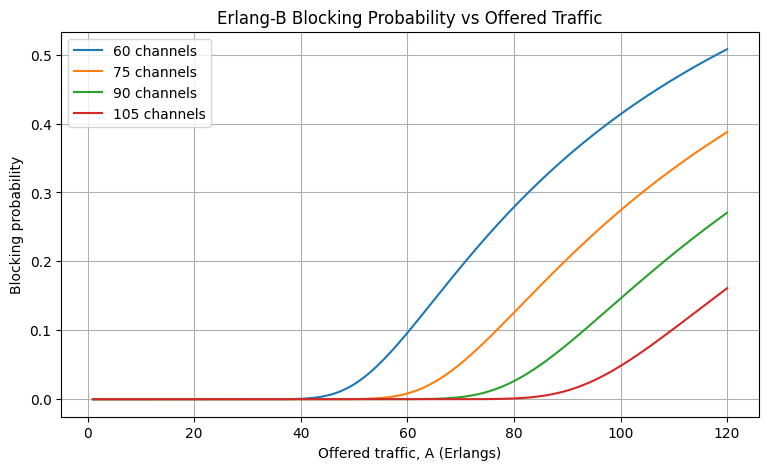

In [5]:
traffic_range = np.linspace(1, 120, 300)
channel_sets = [60, 75, 90, 105]

plt.figure(figsize=(9, 5))
for n_channels in channel_sets:
    blocking = [erlang_b(A, n_channels) for A in traffic_range]
    plt.plot(traffic_range, blocking, label=f"{n_channels} channels")

plt.xlabel("Offered traffic, A (Erlangs)")
plt.ylabel("Blocking probability")
plt.title("Erlang-B Blocking Probability vs Offered Traffic")
plt.legend()
plt.grid(True)
plt.show()

**Observation:** Blocking rises rapidly as offered traffic approaches and exceeds the practical carrying capability of a fixed number of channels. Adding channels shifts the blocking curve downward.

In [6]:
target_gos = 0.02

def minimum_channels_for_gos(offered_traffic, target_blocking, max_channels=500):
    for n_channels in range(1, max_channels + 1):
        if erlang_b(offered_traffic, n_channels) <= target_blocking:
            return n_channels
    return None

min_channels = minimum_channels_for_gos(
    offered_traffic_erlangs,
    target_gos
)

print(f"Minimum channels for A={offered_traffic_erlangs:.1f} Erlangs")
print(f"at GoS B <= {target_gos:.2%}: {min_channels}")

Minimum channels for A=78.3 Erlangs
at GoS B <= 2.00%: 90


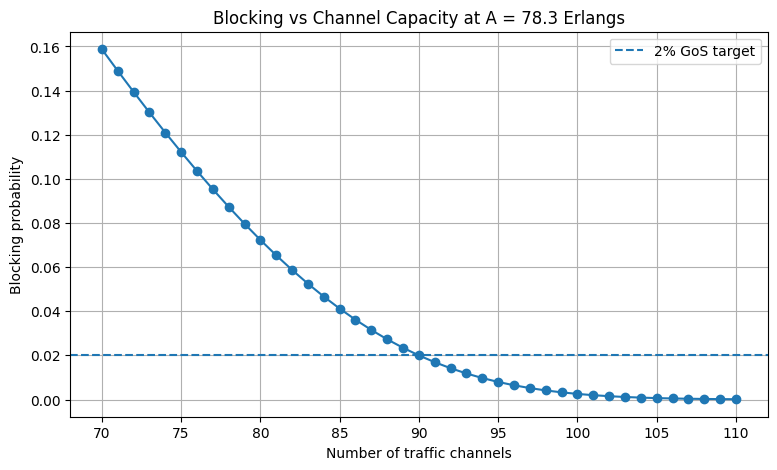

In [7]:
channel_range = np.arange(70, 111)
blocking_by_channels = np.array([
    erlang_b(offered_traffic_erlangs, n) for n in channel_range
])

plt.figure(figsize=(9, 5))
plt.plot(channel_range, blocking_by_channels, marker="o")
plt.axhline(target_gos, linestyle="--", label="2% GoS target")
plt.xlabel("Number of traffic channels")
plt.ylabel("Blocking probability")
plt.title(f"Blocking vs Channel Capacity at A = {offered_traffic_erlangs:.1f} Erlangs")
plt.legend()
plt.grid(True)
plt.show()

## Result and Discussion

For $A=78.3$ Erlangs and $N=90$ channels, Erlang-B blocking is approximately **2%**. The experiment also confirms that more traffic increases blocking while more channels reduce it.

The Erlang-B model assumes blocked calls are cleared rather than queued, so it is appropriate as a simple busy-hour voice-channel model.

## Conclusion

Offered load, calls per hour, channel capacity, and Erlang-B blocking probability were calculated successfully. The simulation also determines the channel count required to meet a target Grade of Service.

## Viva Questions and Short Answers

1. **What is one Erlang?**  
   One channel occupied continuously for one hour.

2. **What is Grade of Service in this experiment?**  
   The accepted call-blocking probability target.

3. **What does Erlang B assume happens to a blocked call?**  
   It is cleared/lost rather than waiting in a queue.

4. **What happens to blocking if offered traffic increases but channels remain fixed?**  
   Blocking probability increases.

5. **What happens to blocking if the number of channels increases for the same traffic?**  
   Blocking probability decreases.

---
[▲ Back to Table of Contents](#toc)
---
